Initial Forest


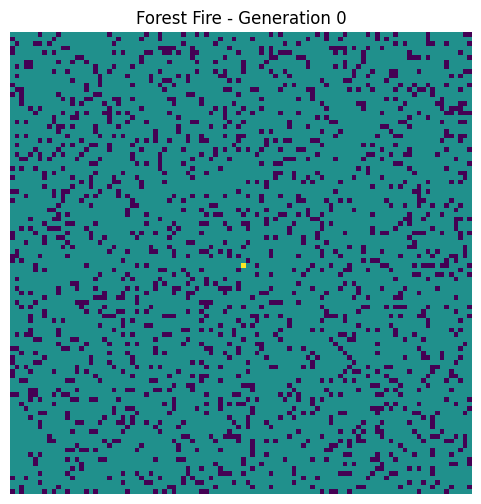

Generation: 5


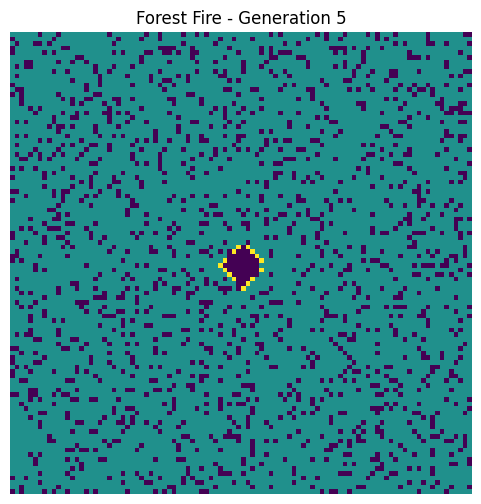

Generation: 10


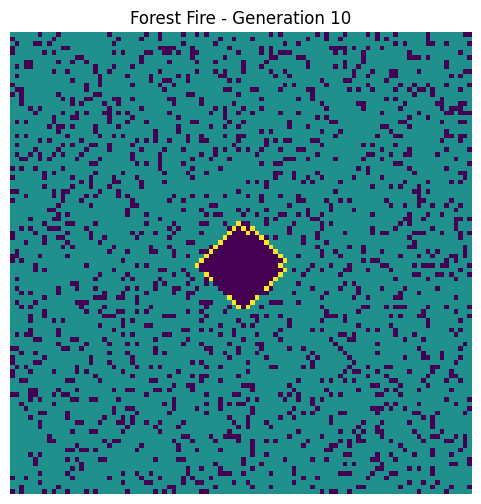

Generation: 15


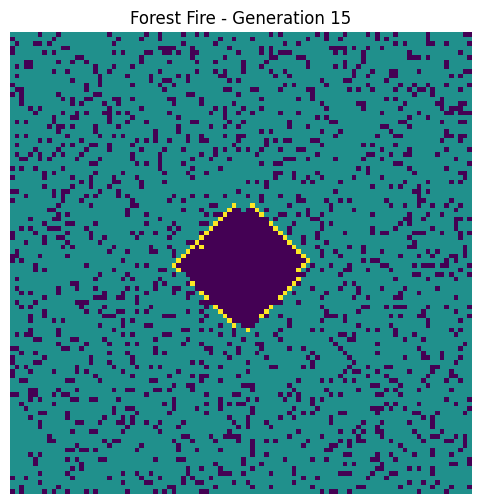

Generation: 20


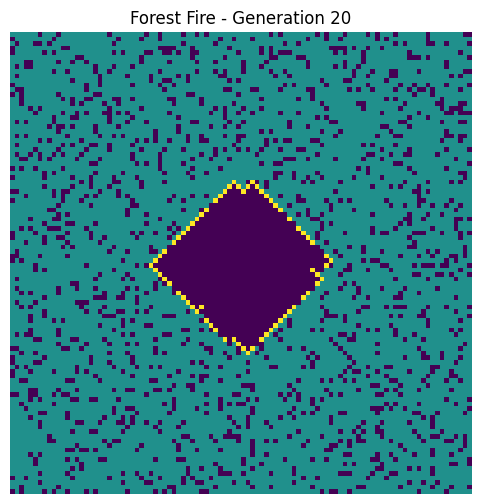

Generation: 25


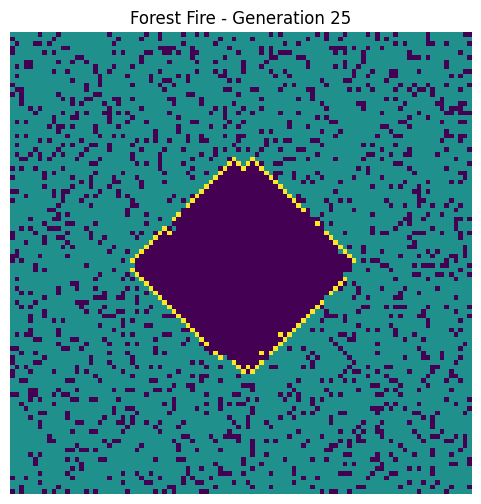

Generation: 30


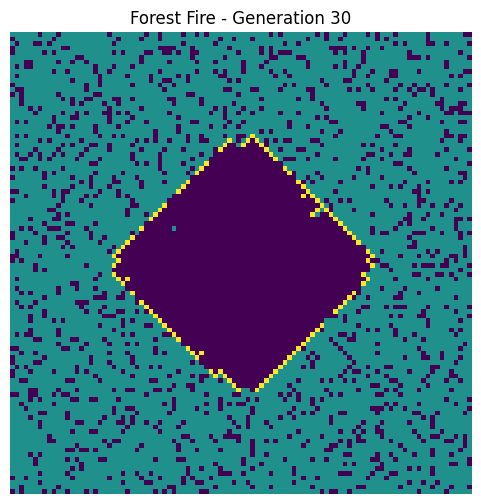

Simulation Completed
Healthy Trees: 6926
Burning Trees: 100
Burned/Empty Cells: 2974
Number of CPU Cores: 2
Processes Used: 4


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from multiprocessing import Pool, cpu_count

SIZE = 100
GENERATIONS = 30
NUM_PROCESSES = 4

EMPTY = 0
HEALTHY = 1
BURNING = 2

np.random.seed(42)

grid = np.ones((SIZE, SIZE), dtype=int)

grid[np.random.random((SIZE, SIZE)) < 0.15] = EMPTY

grid[SIZE // 2, SIZE // 2] = BURNING

def update_section(args):

    grid, start, end = args

    rows, cols = grid.shape

    result = np.zeros((end - start, cols), dtype=int)

    for i in range(start, end):

        for j in range(cols):

            cell = grid[i, j]

            if cell == BURNING:
                result[i - start, j] = EMPTY

            elif cell == HEALTHY:

                neighbors = [
                    grid[(i-1) % rows, j],
                    grid[(i+1) % rows, j],
                    grid[i, (j-1) % cols],
                    grid[i, (j+1) % cols]
                ]

                if BURNING in neighbors:
                    result[i - start, j] = BURNING
                else:
                    result[i - start, j] = HEALTHY

            else:
                result[i - start, j] = EMPTY

    return start, result


def parallel_update(grid):

    rows = grid.shape[0]

    sections = np.linspace(
        0, rows, NUM_PROCESSES + 1, dtype=int
    )

    tasks = []

    for i in range(NUM_PROCESSES):

        start = sections[i]
        end = sections[i + 1]

        tasks.append((grid, start, end))

    with Pool(NUM_PROCESSES) as pool:

        results = pool.map(update_section, tasks)

    new_grid = np.zeros_like(grid)

    for start, section in results:

        new_grid[start:start + len(section)] = section

    return new_grid


def display_grid(grid, generation):

    plt.figure(figsize=(6, 6))

    plt.imshow(
        grid,
        cmap="viridis",
        vmin=0,
        vmax=2
    )

    plt.title("Forest Fire - Generation " + str(generation))
    plt.axis("off")
    plt.show()


print("Initial Forest")
display_grid(grid, 0)

for generation in range(1, GENERATIONS + 1):

    grid = parallel_update(grid)

    if generation % 5 == 0:

        print("Generation:", generation)

        display_grid(grid, generation)

print("Simulation Completed")

print("Healthy Trees:", np.sum(grid == HEALTHY))
print("Burning Trees:", np.sum(grid == BURNING))
print("Burned/Empty Cells:", np.sum(grid == EMPTY))

print("Number of CPU Cores:", cpu_count())
print("Processes Used:", NUM_PROCESSES)